Name: Daniel Vella\
Course: B.Sc. in Computing Science and Mathematics\
ID: 0147005L\
Date: 14/04/2025

Importing all necessary libraries:

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import random
import time
from sklearn.datasets import make_circles
from sklearn.datasets import make_blobs
from sklearn import neighbors

# Task 1
Generate the following synthetic binary classification datasets using the sklearn.datasets. For
both datasets generate scatter plots, the distribution of the output labels and the mean and
standard deviation of all input variables (features).

a) Generate a dataset from make_circles with the following options; n_samples=1000,
random_state=0, noise=0.2, factor =0.6, and inputs=2

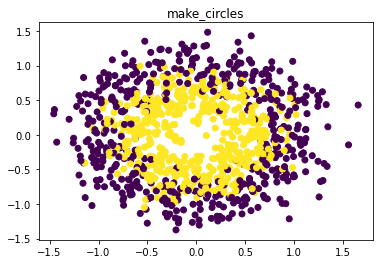

There are 500 0s and 500 1s.
The mean of the 1st input variable is 0.002443190119914531.
The mean of the 2nd input variable is -0.0025167646171500363.
The standard deviation of the 1st input variable is 0.6158257970105208.
The standard deviation of the 2nd input variable is 0.616477375635193.


In [6]:
circ1, circ2 = make_circles(n_samples=1000,random_state=0,noise=0.2,factor=0.6)

#combining the points and the labels into one array of the form [x,y,b]
circ = np.empty((circ1.shape[0],3))
circ[:,0] = circ1[:,0]
circ[:,1] = circ1[:,1]
circ[:,2] = circ2[:]

#scatter
plt.figure()
fig = plt.subplot()
fig.scatter(circ[:,0],circ[:,1], c=circ[:,2])
fig.set_title("make_circles")
plt.show()

#distribution
count = int(np.sum(np.array(circ[:,2])))        
print("There are",(1000-count),"0s and",count,"1s.")

#mean
mean = [np.mean(circ[:,0]),np.mean(circ[:,1])]
print("The mean of the 1st input variable is",mean[0],end=".\n")
print("The mean of the 2nd input variable is",mean[1],end=".\n")

#standard deviation
std = [np.std(circ[:,0]),np.std(circ[:,1])]
print("The standard deviation of the 1st input variable is",std[0],end=".\n")
print("The standard deviation of the 2nd input variable is",std[1],end=".\n")




b) Generate a dataset from make_blobs with the following options (n_samples=1000,
centers=2, cluster_std=1.0, n_features=2, random_state=0)

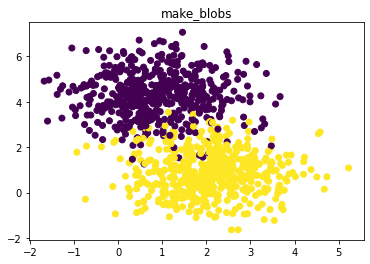

There are 500 0s and 500 1s.
The mean of the 1st input variable is 1.489802739279975.
The mean of the 2nd input variable is 2.585510815852406.
The standard deviation of the 1st input variable is 1.1343317178294197.
The standard deviation of the 2nd input variable is 1.953900431588933.


In [7]:
blob1, blob2 = make_blobs(n_samples=1000,centers=2,random_state=0)
#default values are valid for the other attributes

#combining the points and the labels into one array of the form [x,y,b]
blob = np.empty((blob1.shape[0],3))
blob[:,0] = blob1[:,0]
blob[:,1] = blob1[:,1]
blob[:,2] = blob2[:]


#scatter
plt.figure()
fig = plt.subplot()
fig.scatter(blob[:,0],blob[:,1],c=blob[:,2])
fig.set_title("make_blobs")
plt.show()

#distribution
count = int(np.sum(np.array(blob[:,2])))        
print("There are",(1000-count),"0s and",count,"1s.")

#mean
mean = [np.mean(blob[:,0]),np.mean(blob[:,1])]
print("The mean of the 1st input variable is",mean[0],end=".\n")
print("The mean of the 2nd input variable is",mean[1],end=".\n")

#standard deviation
std = [np.std(blob[:,0]),np.std(blob[:,1])]
print("The standard deviation of the 1st input variable is",std[0],end=".\n")
print("The standard deviation of the 2nd input variable is",std[1],end=".\n")



# Task 2 #
Develop the following functions in Python from scratch: 

 
a) A function that re-shuffles and splits the dataset into two portions

In [4]:
def shuffle(X,ratio, random_seed=None) :
    #takes an ndarray and what percentage of the total size to keep in the training set
    size = X.shape[0]
    finalsize = int(size*(ratio/100))
    
    if random_seed != None : 
        random.seed(random_seed)
    
    a = random.sample(range(size),size)
        
    X = X.tolist()
    
    for i in range(size) :
        X[i], X[a[i]] = X[a[i]], X[i]
        
    X1 = X[finalsize:]
    X = X[:finalsize]
                
    return np.array(X),np.array(X1)
    
def shuffletest() :
    X = np.array([i for i in range(1,21)])
    print(X,X.shape[0])
    X,X1 = shuffle(X,60,random_seed=0)
    print(X,X1)
    print(X.shape[0],X1.shape[0])

shuffletest()


[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20] 20
[ 5  3  1 12  8 10 20  4 16 11  6  2] [14  9 17 13 15 18 19  7]
12 8


b) A function that computes and returns the classification accuracy, recall, precision, and F1-score for a binary classification task.

In [8]:
def properties(trueY, predY) :
    #summing all the 1s that appear after a logical and gives each attribute depending on the elements compared
    TP = np.sum(np.logical_and(trueY,predY).astype(int))
    TN = np.sum(np.logical_not(np.logical_or(trueY,predY)).astype(int))
    FP = np.sum(np.logical_and(np.logical_not(trueY),predY).astype(int))
    FN = np.sum(np.logical_and(trueY,np.logical_not(predY)).astype(int))
    
    accuracy = (TP + TN)/(TP + TN + FP + FN)
    recall = TP/(TP + FN)
    precision = TP/(TP + FP)
    F1score = 2*(precision * recall)/(precision + recall)
    
    return accuracy, recall, precision, F1score


from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

def propertiestest() :
    Y1 = np.array([0,1,1,0,1,1,0,0,1,0])
    Y2 = np.array([0,1,1,1,0,1,0,1,0,1])
    
    test = np.empty(4)
    true = np.empty(4)
    test[0], test[1], test[2], test[3] = properties(Y1, Y2)
    true[0], true[1], true[2], true[3] = accuracy_score(Y1,Y2), recall_score(Y1,Y2), precision_score(Y1,Y2), f1_score(Y1,Y2)
    
    #comparing the function created from scratch to those given by the sklearn library
    if(all(test) == all(true)) : print("True") 
    else : print("False")

propertiestest()
    

True


# Task 3
Develop a k-NN model for each dataset in task 1:


a) Using the function developed in task 2, split the dataset into a train set and test set in the ratio 80%/20% respectively.

In [9]:
#selecting a random seed for testing purposes
random_seed = 0

circinitialtrain, circtest = shuffle(circ, 80, random_seed)
blobinitialtrain, blobtest = shuffle(blob, 80, random_seed)

b) Find the best k that maximises the F1-score (use the function developed in task 2 to compute F1 and you may want to split the train set further into train/validation)

c) Find the best k that maximises accuracy (use function developed in task 2 to compute 
accuracy and you may want to split the train set further into train/validation)

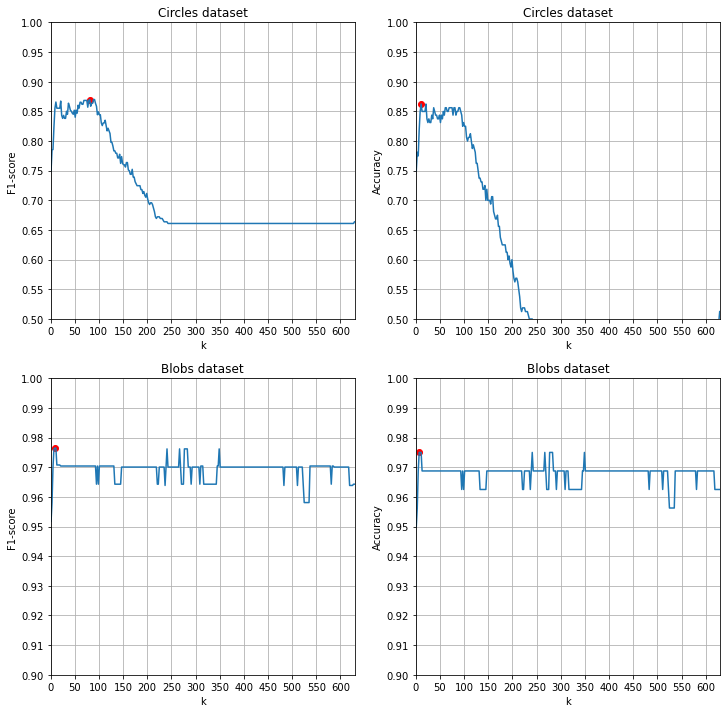

Max F1 score (0.8700564971751412) for circles is given by k = 81.
Max accuracy (0.8625) for circles is given by k = 11.
Max F1 score (0.9764705882352942) for blobs is given by k = 9.
Max accuracy (0.975) for blobs is given by k = 7.


In [10]:
#computing for circles dataset
circtrain, circval = shuffle(circinitialtrain, 80, random_seed)
ks = [k for k in range(1, 630, 2)]
F1s = []
accs = []

#obtaining the accuracy and the F1-scores for each k in the circles dataset
for k in ks :
    clf = neighbors.KNeighborsClassifier(k)
    clf.fit(circtrain[:,(0,1)], circtrain[:,2])

    circpred = clf.predict(circval[:,(0,1)])
    acc, rec, prec, F1 = properties(circval[:,2], circpred)
    accs.append(acc)
    F1s.append(F1)

fig1, ((F1circfig, acccircfig), (F1blobfig, accblobfig)) = plt.subplots(2,2)
fig1.set_size_inches(12,12)

F1circfig.plot(ks,F1s)
F1circfig.set_xlabel("k")
F1circfig.set_ylabel("F1-score")
F1circfig.set_title("Circles dataset")
F1circfig.set_yticks(np.arange(0.5,1.001,0.05))
F1circfig.set_ylim(0.5,1.0)
F1circfig.set_xticks(np.arange(0,631,50))
F1circfig.set_xlim(0,630)
F1circfig.grid(True)

acccircfig.plot(ks,accs)
acccircfig.set_xlabel("k")
acccircfig.set_ylabel("Accuracy")
acccircfig.set_title("Circles dataset")
acccircfig.set_yticks(np.arange(0.5,1.001,0.05))
acccircfig.set_ylim(0.5,1.0)
acccircfig.set_xticks(np.arange(0,631,50))
acccircfig.set_xlim(0,630)
acccircfig.grid(True)

circmaxF1 = max(F1s)
circmaxacc = max(accs)
F1circmaxk = ks[F1s.index(circmaxF1)]
acccircmaxk = ks[accs.index(circmaxacc)]


#obtaining the accuracy and the F1-scores for each k in the circles dataset
blobtrain, blobval = shuffle(blobinitialtrain, 80, random_seed)
F1s = []
accs = []
for k in ks :
    clf = neighbors.KNeighborsClassifier(k)
    clf.fit(blobtrain[:,(0,1)], blobtrain[:,2])

    blobpred = clf.predict(blobval[:,(0,1)])
    acc, rec, prec, F1 = properties(blobval[:,2], blobpred)
    F1s.append(F1)
    accs.append(acc)

F1blobfig.plot(ks,F1s)
F1blobfig.set_xlabel("k")
F1blobfig.set_ylabel("F1-score")
F1blobfig.set_title("Blobs dataset")
F1blobfig.set_yticks(np.arange(0.9,1.005,0.01))
F1blobfig.set_ylim(0.9,1.0)
F1blobfig.set_xticks(np.arange(0,631,50))
F1blobfig.set_xlim(0,630)
F1blobfig.grid(True)

accblobfig.plot(ks,accs)
accblobfig.set_xlabel("k")
accblobfig.set_ylabel("Accuracy")
accblobfig.set_title("Blobs dataset")
accblobfig.set_yticks(np.arange(0.9,1.005,0.01))
accblobfig.set_ylim(0.9,1.0)
accblobfig.set_xticks(np.arange(0,631,50))
accblobfig.set_xlim(0,630)
accblobfig.grid(True)

blobmaxF1 = max(F1s)
blobmaxacc = max(accs)
F1blobmaxk = ks[F1s.index(blobmaxF1)]
accblobmaxk = ks[accs.index(blobmaxacc)]

F1circfig.scatter(F1circmaxk, circmaxF1, color='red')
acccircfig.scatter(acccircmaxk, circmaxacc, color='red')
F1blobfig.scatter(F1blobmaxk, blobmaxF1, color='red')
accblobfig.scatter(accblobmaxk,blobmaxacc, color='red')

plt.show()

print("Max F1 score (", circmaxF1, ") for circles is given by k = ", F1circmaxk, sep="", end=".\n")
print("Max accuracy (", circmaxacc, ") for circles is given by k = ", acccircmaxk, sep="", end=".\n")
print("Max F1 score (", blobmaxF1, ") for blobs is given by k = ", F1blobmaxk, sep="", end=".\n")
print("Max accuracy (", blobmaxacc, ") for blobs is given by k = ", accblobmaxk, sep="", end=".\n")

Based on the results obtained from the validation set, we can fit a new model on the best k depending on whether F1-score or accuracy is to be prioritised for the test set. In the example below, accuracy was prioritised for the circles dataset.

In [ ]:
clf = neighbors.KNeighborsClassifier(acccircmaxk)
clf.fit(circinitialtrain[:,(0,1)], circinitialtrain[:,2])
circfinalpred = clf.predict(circtest[:,(0,1)])

# Task 4

In this task you will empirically carry out a time complexity analysis of both the standard brute
search and the kdTree search methods. Both algorithms are parameter values in the sci-kit learn
kNN class. For this study you will use the synthetically generated datasets from task 1 with the
option of varying the dataset size.

a) Design and describe a computational experiment to compare the time complexity of the 
two algorithms during inference (prediction). In other words, you have to measure the
computational time taken for the models to infer the category for a fixed number of test 
samples given various training set sizes, for example, size = 100, 1000, 10000, etc. 

In order to time how long it takes each model to determine the category of an increasing sample size, the perf_counter function from Python's time module will be used. This function was chosen over other options such as timeit due to its very high precision to ensure accurate test results. $\\$
The set sizes which will be used for this experiment range from 500 to 10,000, incrementing by 50 between each iteration, with a fixed test set size of 100. The time taken for the function to run 10,000 times will be recorded, to minimise the effect of background processes on the timing of the function. An arbitrary k-value of 5 was chosen for all set sizes, since this needs to be kept constant to ensure that the only variable in the experiment is the training set size.

b) Implement the experiment in Python and extract the results.

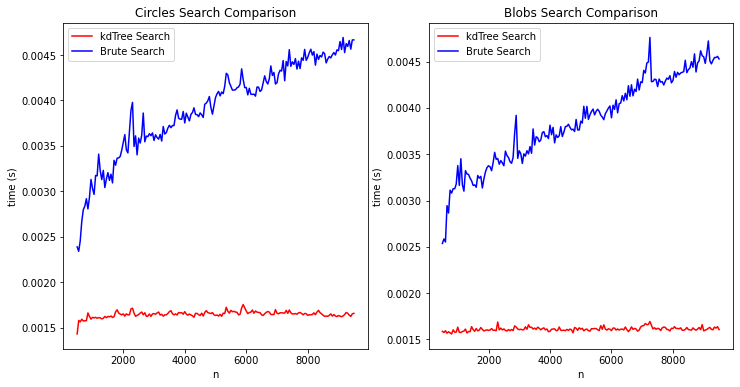

In [11]:
#redefining circX, circY, circ, blobX, blobY, blob within a loop to facilitate increasing set size

ns = [(i * 50) + 500 for i in range(181)] #[500,550,600,...,10000]
testsplitratios = [((n-100)/n) * 100 for n in ns] #[80,81.81,83.33,...,99]
k = 5

circtreetimes, circbrutetimes = [], []
for n in ns :
    circ1, circ2 = make_circles(n_samples=n, random_state=0, noise=0.2, factor=0.6)
    
    #combining points and labels into one array
    circ = np.empty((circ1.shape[0],3))
    circ[:,0] = circ1[:,0]
    circ[:,1] = circ1[:,1]
    circ[:,2] = circ2[:]
    
    circtrain, circtest = shuffle(circ, testsplitratios[ns.index(n)], random_seed)
    #print(n)
    
    clf = neighbors.KNeighborsClassifier(k,algorithm='kd_tree')
    clf.fit(circtrain[:,(0,1)], circtrain[:,2])
        
    #clearing overhead of first few calls
    for _ in range(5) :
        _ = clf.predict(circtest[:,(0,1)])

    #averaging over 10000 iterations
    start = time.perf_counter()    
    for _ in range(10000):
        _ = clf.predict(circtest[:,(0,1)])
    end = time.perf_counter()
            
    circtreetimes.append((end - start) / 10000)
        
    clf = neighbors.KNeighborsClassifier(k,algorithm='brute')
    clf.fit(circtrain[:,(0,1)], circtrain[:,2])
        
    #clearing overhead of first few calls
    for _ in range(5) :
        _ = clf.predict(circtest[:,(0,1)])

    #averaging over 10000 iterations
    start = time.perf_counter()    
    for _ in range(10000):
        _ = clf.predict(circtest[:,(0,1)])
    end = time.perf_counter()
            
    circbrutetimes.append((end - start) / 10000)


blobtreetimes, blobbrutetimes = [], []
for n in ns :
    blob1, blob2 = make_blobs(n_samples=n,centers=2,random_state=0)
    
    #combining points and labels into one array
    blob = np.empty((blob1.shape[0],3))
    blob[:,0] = blob1[:,0]
    blob[:,1] = blob1[:,1]
    blob[:,2] = blob2[:]
    
    blobtrain, blobtest = shuffle(blob, testsplitratios[ns.index(n)], random_seed)
    #print(n)
    
    clf = neighbors.KNeighborsClassifier(k,algorithm='kd_tree')
    clf.fit(blobtrain[:,(0,1)], blobtrain[:,2])
        
    #clearing overhead of first few calls
    for _ in range(5) :
        _ = clf.predict(circtest[:,(0,1)])
    
    #averaging over 10000 iterations
    start = time.perf_counter()    
    for _ in range(10000):
        _ = clf.predict(blobtest[:,(0,1)])
    end = time.perf_counter()
        
    blobtreetimes.append((end - start) / 10000)
        
    clf = neighbors.KNeighborsClassifier(k,algorithm='brute')
    clf.fit(blobtrain[:,(0,1)], blobtrain[:,2])
    
    #clearing overhead of first few calls
    for _ in range(5) :
        _ = clf.predict(circtest[:,(0,1)])
        
    #averaging over 10000 iterations
    start = time.perf_counter()    
    for _ in range(10000):
        _ = clf.predict(blobtest[:,(0,1)])
    end = time.perf_counter()
        
    blobbrutetimes.append((end - start) / 10000)
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.plot(ns, circtreetimes, color='red', label='kdTree Search')
ax1.plot(ns, circbrutetimes, color='blue', label='Brute Search')
ax1.set_xlabel("n")
ax1.set_ylabel("time (s)")
ax1.set_title("Circles Search Comparison")
ax1.legend()

ax2.plot(ns, blobtreetimes, color='red', label='kdTree Search')
ax2.plot(ns, blobbrutetimes, color='blue', label='Brute Search')
ax2.set_xlabel("n")
ax2.set_ylabel("time (s)")
ax2.set_title("Blobs Search Comparison")
ax2.legend()
plt.show()

c) Discuss the outcome of the experiment. Do the results corroborate theoretical analysis?

The graphs obtained after running this experiment show that initially the K-D Tree search takes a bit more than half the time needed for the Brute Force search algorithm, but as the set size increases the time taken for the K-D Tree search algorithm to run increases at a much smaller rate than for the Brute Force search one. Through theoretical analysis (obtained from [sk-learn documentation](https://scikit-learn.org/stable/modules/neighbors.html)) we know that the time complexity for the Brute Force search grows as $O[N]$, while for the K-D Tree search it grows as $O[log(N)]$, which can be clearly seen in the graphs of time against size obtained above. Thus these results do corroborate theoretical analysis.

# References
- Documentation: 
    * Numpy: [numpy.org](https://numpy.org/)
    * Scikit-Learn: [scikit-learn.org/stable/index.html](https://scikit-learn.org/stable/index.html)
    * Matplotlib: [matplotlib.org/stable/](https://matplotlib.org/stable/)
    * Time: [docs.python.org/3/library/time.html](https://docs.python.org/3/library/time.html)
    * Random: [docs.python.org/3/library/random.html](https://docs.python.org/3/library/random.html) 
- Generative AI: [chatgpt.com](https://chatgpt.com)
    * See attached document for list of prompts and notes on what was used.
- knn_athletes.ipynb example notebook provided on VLE